# Find the best offered price

Run inside the workspace created by Notebook 01. We compare the same hotel under different demand levels. Each sale permanently consumes one room; inventory can only stay the same or fall by one each day.

**Predict first:** at a fixed number of days before check-in and a fixed remaining room count, which demand condition should produce the highest offered price?

In [ ]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from IPython.display import display
import yaml

with open('config.yaml', encoding='utf-8') as file:
    config = yaml.safe_load(file)
assert config.get('workflow') == 'pricing-workshop-v1', 'Generate a fresh workspace with Notebook 01 first.'

def load_model(name):
    with open(f'model/{name}.pickle', 'rb') as file:
        return pickle.load(file)

price_min, price_max, price_interval = load_model('opt_table_params')
mu, sigma = load_model('wtp_parameters')
visit_curve = load_model('visit_curve')
price_grid = np.arange(price_min, price_max, price_interval)
figure_dir = Path('fig/pricing')
figure_dir.mkdir(parents=True, exist_ok=True)
Path('result').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

## Two possible outcomes: sale or no sale

Let $t$ be days before check-in and $c$ the number of rooms still available. A potential customer arrives with probability $a_t$. At price $p$, the purchase probability is $d(p) = \Pr(\mathrm{WTP} \geq p)$.

The probability of a sale is $s(t,p) = a_t d(p)$. Let $V(t,c)$ be optimal expected future revenue. The expected revenue from choosing $p$ is:

$$
s(t,p)\left[p + V(t-1,c-1)\right] + \left[1-s(t,p)\right]V(t-1,c).
$$

We evaluate every allowed price and keep the one with the highest expected revenue. With zero rooms, expected future revenue is zero and sales are closed. After the last period, expected future revenue is also zero. At $t=0$, only today's possible sale matters.

The code works backwards from $t=0$ to larger lead times. `norm.sf` computes the normal tail probability directly. Values are not rounded during optimisation. If multiple prices tie, the lowest price in the grid is selected.

In [ ]:
def create_optimized_price_table(arrival_probabilities, prices, mean_wtp, std_wtp, capacity):
    """Dynamic programming for permanent sales, with one arrival opportunity per day."""
    arrival = np.asarray(arrival_probabilities, dtype=float)
    prices = np.asarray(prices, dtype=float)
    if arrival.ndim != 1 or len(arrival) == 0 or not np.all(np.isfinite(arrival)) or np.any((arrival < 0) | (arrival > 1)):
        raise ValueError('Daily arrival probabilities must lie between zero and one.')
    if prices.ndim != 1 or len(prices) == 0 or not np.all(np.isfinite(prices)) or np.any(prices <= 0) or np.any(np.diff(prices) <= 0):
        raise ValueError('The price grid must be positive, finite and strictly increasing.')
    if isinstance(capacity, bool) or not isinstance(capacity, int) or capacity < 0:
        raise ValueError('Capacity must be a non-negative integer.')
    if not np.isfinite(mean_wtp) or not np.isfinite(std_wtp) or std_wtp <= 0:
        raise ValueError('WTP parameters must be finite, with positive standard deviation.')
    purchase_probability = norm.sf(prices, loc=mean_wtp, scale=std_wtp)
    optimal_prices = np.full((len(arrival), capacity + 1), np.inf)
    expected_revenue = np.zeros((len(arrival), capacity + 1))
    previous = np.zeros(capacity + 1)
    for t, arrival_probability in enumerate(arrival):
        sale_probability = arrival_probability * purchase_probability
        for rooms in range(1, capacity + 1):
            candidate_revenue = (
                sale_probability * (prices + previous[rooms - 1])
                + (1 - sale_probability) * previous[rooms]
            )
            best = int(np.argmax(candidate_revenue))
            optimal_prices[t, rooms] = prices[best]
            expected_revenue[t, rooms] = candidate_revenue[best]
        previous = expected_revenue[t].copy()
    return pd.DataFrame(optimal_prices), pd.DataFrame(expected_revenue)

In [ ]:
opt_price, opt_revenue = {}, {}
for multiplier in config['mt_multiplier']:
    arrival = visit_curve['visit'].to_numpy() * config['people'] * multiplier
    opt_price[multiplier], opt_revenue[multiplier] = create_optimized_price_table(
        arrival, price_grid, mu, sigma, config['capacity'])
    print(f'Demand x {multiplier:g}: expected potential arrivals = {arrival.sum():.1f}')

for name, tables in [('opt_price', opt_price), ('opt_revenue', opt_revenue)]:
    with open(f'model/{name}.pickle', 'wb') as file:
        pickle.dump(tables, file)

rows = []
for multiplier, table in opt_price.items():
    for t in table.index:
        for rooms in table.columns:
            rows.append({'demand_multiplier': multiplier, 'days_before_checkin': t,
                         'remaining_rooms': rooms, 'price': table.loc[t, rooms],
                         'expected_revenue': opt_revenue[multiplier].loc[t, rooms]})
price_results = pd.DataFrame(rows)
price_results.to_csv('result/price_tables.csv', index=False)
display(price_results.head())

Demand x 0.6: expected potential arrivals = 10.8
Demand x 1: expected potential arrivals = 18.0
Demand x 1.2: expected potential arrivals = 21.6


,demand_multiplier,days_before_checkin,remaining_rooms,price,expected_revenue
0,0.6,0,0,inf,0.000000
1,0.6,0,1,14000.0,10.891512
2,0.6,0,2,14000.0,10.891512
3,0.6,0,3,14000.0,10.891512
4,0.6,0,4,14000.0,10.891512


## Compare price tables on the same colour scale

Rows are days before check-in and columns are remaining rooms. The first row is the beginning of the booking horizon. Zero-room states are excluded from the heatmaps because sales are closed there.

Compare **the same cell** across demand levels. A different colour means a different recommended price, not a different probability.

The tables below the heatmaps show every price, with the same lead-time order. Prices are rounded to whole currency units for display (half up) and use thousands separators. The zero-room column shows **Closed**. Calculations and exported CSV values retain their original precision.

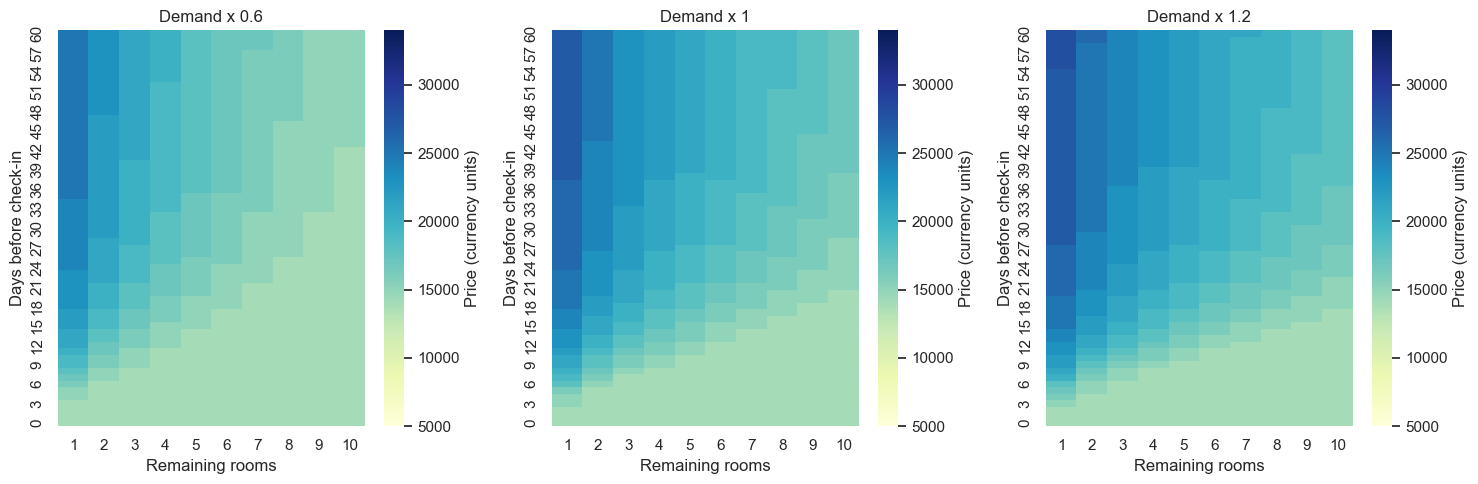

In [ ]:
multipliers = config['mt_multiplier']
fig, axes = plt.subplots(1, len(multipliers), figsize=(5 * len(multipliers), 5), squeeze=False)
for ax, multiplier in zip(axes[0], multipliers):
    table = opt_price[multiplier].iloc[::-1, 1:]
    sns.heatmap(table, ax=ax, cmap='YlGnBu', vmin=price_grid.min(), vmax=price_grid.max(),
                cbar_kws={'label': 'Price (currency units)'})
    ax.set(title=f'Demand x {multiplier:g}', xlabel='Remaining rooms', ylabel='Days before check-in')
fig.tight_layout()
fig.savefig(figure_dir / 'price_tables.png', dpi=140, bbox_inches='tight')
plt.show()
plt.close(fig)

In [ ]:
from decimal import Decimal, ROUND_HALF_UP


def format_display_price(value):
    """Round only the displayed price; keep the underlying table unchanged."""
    if np.isinf(value):
        return 'Closed'
    rounded = Decimal(str(value)).quantize(Decimal('1'), rounding=ROUND_HALF_UP)
    return f'{rounded:,}'


for multiplier in multipliers:
    price_table = opt_price[multiplier].iloc[::-1].rename_axis(
        index='Days before check-in', columns='Remaining rooms')
    display(price_table.style
            .format(format_display_price)
            .set_caption(f'Optimal prices — Demand x {multiplier:g} (currency units)'))

Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","17,000","16,000","15,000","15,000"
59,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","17,000","16,000","15,000","15,000"
58,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","17,000","16,000","15,000","15,000"
57,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
56,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
55,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
54,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
53,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
52,Closed,"25,000","23,000","21,000","19,000","18,000","17,000","16,000","16,000","15,000","15,000"


Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
59,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
58,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
57,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
56,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
55,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
54,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
53,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
52,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"


Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,Closed,"28,000","26,000","24,000","23,000","22,000","21,000","21,000","20,000","19,000","18,000"
59,Closed,"28,000","26,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
58,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
57,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
56,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
55,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
54,Closed,"27,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
53,Closed,"27,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
52,Closed,"27,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"


## Focus on one inventory level

Change `remaining_rooms` below and rerun this cell. This does not change the hotel's total capacity; it selects a column from the calculated tables.

**Discuss:** What happens when only two rooms remain? Does the recommended price stay the same as check-in approaches? The right-hand plot shows differences from baseline demand.

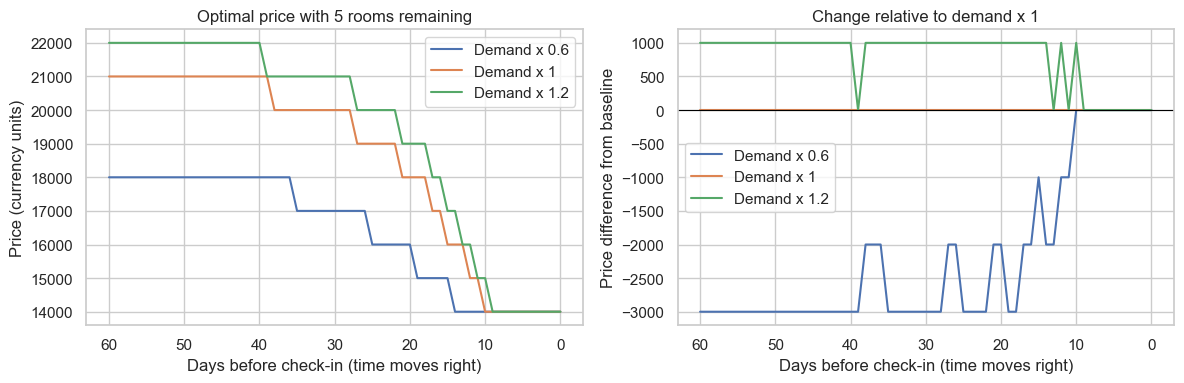

In [ ]:
remaining_rooms = min(5, config['capacity'])  # Try 2, 5 or 10 (up to capacity).
if not 1 <= remaining_rooms <= config['capacity']:
    raise ValueError('Choose a remaining room count between 1 and capacity.')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for multiplier in multipliers:
    series = opt_price[multiplier][remaining_rooms]
    axes[0].plot(series.index, series, label=f'Demand x {multiplier:g}')
    axes[1].plot(series.index, series - opt_price[1.0][remaining_rooms], label=f'Demand x {multiplier:g}')
for ax in axes:
    ax.invert_xaxis()
    ax.set_xlabel('Days before check-in (time moves right)')
    ax.legend()
axes[0].set(ylabel='Price (currency units)', title=f'Optimal price with {remaining_rooms} rooms remaining')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(ylabel='Price difference from baseline', title='Change relative to demand x 1')
fig.tight_layout()
fig.savefig(figure_dir / 'price_comparison.png', dpi=140, bbox_inches='tight')
plt.show()
plt.close(fig)

## Check and explain

Expected revenue is non-negative. Adding inventory or more selling periods cannot reduce the optimal expected revenue in this model: extra opportunities need not be used. These checks validate values; they do not force a desired price trend.

Price changes can be stepwise because the available prices are on a discrete grid. A change in demand does not have to change every cell.

In [ ]:
for multiplier in multipliers:
    prices = opt_price[multiplier].to_numpy()
    revenue = opt_revenue[multiplier].to_numpy()
    assert np.isinf(prices[:, 0]).all()
    assert np.isin(prices[:, 1:], price_grid).all()
    assert np.isfinite(revenue).all() and (revenue >= 0).all()
    assert np.allclose(revenue[:, 0], 0)
    assert (np.diff(revenue, axis=0) >= -1e-8).all()
    assert (np.diff(revenue, axis=1) >= -1e-8).all()
print('All price-table checks passed.')

All price-table checks passed.


## Explain your result to a partner

- What assumption did you change, or which inventory column did you compare?
- What did you predict before calculating?
- Where did the price change, and where did it stay the same?
- How does the possibility of a future sale affect the decision to accept a lower price now?

To explore another WTP mean or arrival distribution, edit the scenario and use Notebook 01 to generate a new workspace. This workbook ends at optimal pricing. The outputs are deterministic expected values, not sampled outcomes.